In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('titanic_data_updated.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
df.shape

(891, 12)

In [ ]:
print(f"Total features: {df.shape[1]}")
print(f"Total samples: {df.shape[0]}")

Total features: 12
Total samples: 891


In [ ]:
df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
581,582,yes,first,"Thayer, Mrs. John Borland (Marian Longstreth M...",female,39.0,1,1,17421,110.8833,C68,C
59,60,no,third,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9000,NaN,S
228,229,no,second,"Fahlstrom, Mr. Arne Jonas",male,18.0,0,0,236171,13.0000,NaN,S
137,138,no,first,"Futrelle, Mr. Jacques Heath",male,37.0,1,0,113803,53.1000,C123,S
14,15,no,third,"Vestrom, Miss. Hulda Amanda Adolfina",female,14.0,0,0,350406,7.8542,NaN,S
329,330,yes,first,"Hippach, Miss. Jean Gertrude",female,16.0,0,1,111361,57.9792,B18,C
438,439,no,first,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
591,592,yes,first,"Stephenson, Mrs. Walter Bertram (Martha Eustis)",female,52.0,1,0,36947,78.2667,D20,C
293,294,no,third,"Haas, Miss. Aloisia",female,24.0,0,0,349236,8.8500,NaN,S
315,316,yes,third,"Nilsson, Miss. Helmina Josefina",female,26.0,0,0,347470,7.8542,NaN,S


In [ ]:
# Want to see the missing values

df.isnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
# Checking duplicates

df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
886,False
887,False
888,False
889,False


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Deleting duplicates

df.drop_duplicates(inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


## Univariate Analysis (For categorical values)

<Axes: xlabel='Survived', ylabel='count'>

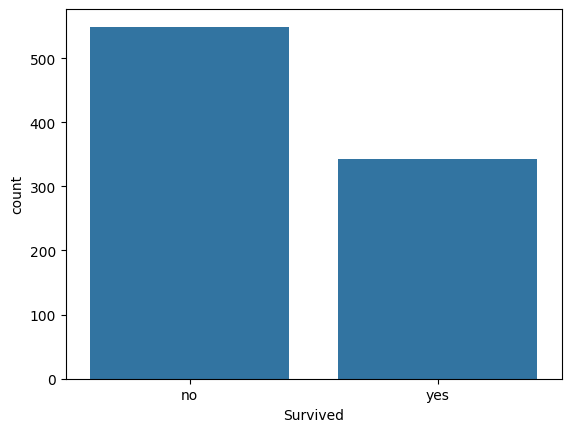

In [ ]:
sns.countplot(data=df, x=df['Survived'])

In [ ]:
df['Survived'].value_counts()

,count
Survived,
no,549
yes,342


In [ ]:
# Percantage of survived people

(df['Survived'].value_counts() / len(df)) * 100

,count
Survived,
no,61.616162
yes,38.383838


In [ ]:
survived_and_not_survived_count = df['Survived'].value_counts()
survived_and_not_survived_label = df['Survived'].unique()

print(survived_and_not_survived_label)

['no' 'yes']


([<matplotlib.patches.Wedge at 0x7899ae0634d0>,
 [Text(-0.39257494735793463, 1.0275626067091557, 'no'),
  Text(0.3925749146953058, -1.0275626191877425, 'yes')],
 [Text(-0.21413178946796432, 0.5604886945686304, '61.6'),
  Text(0.21413177165198496, -0.5604887013751322, '38.4')])

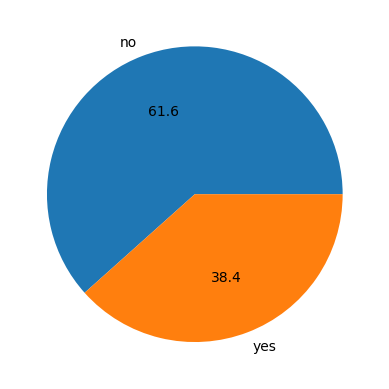

In [ ]:
plt.pie(survived_and_not_survived_count, labels = survived_and_not_survived_label, autopct="%1.1f")

<Axes: xlabel='Pclass', ylabel='count'>

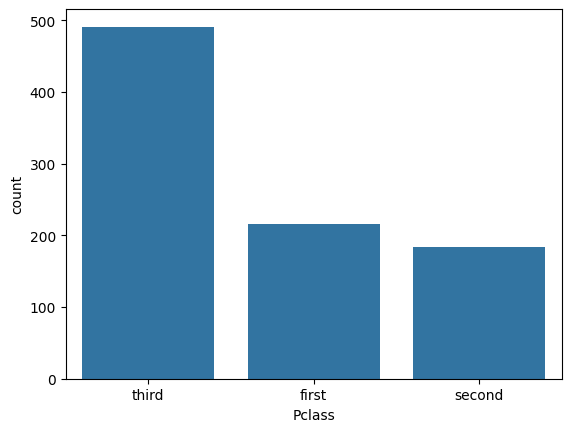

In [ ]:
sns.countplot(data=df, x=df['Pclass'])

In [ ]:
pclass_count = df['Pclass'].value_counts()

pclass_count

,count
Pclass,
third,491
first,216
second,184


In [ ]:
(df['Pclass'].value_counts() / len(df)) * 100

,count
Pclass,
third,55.106622
first,24.242424
second,20.650954


<Axes: xlabel='Sex', ylabel='count'>

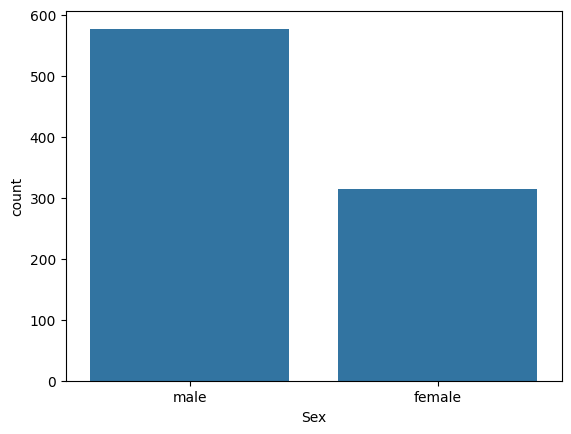

In [ ]:
sns.countplot(data=df, x=df['Sex'])

In [ ]:
(df['Sex'].value_counts() / len(df)) * 100

,count
Sex,
male,64.758698
female,35.241302


<Axes: xlabel='Embarked', ylabel='count'>

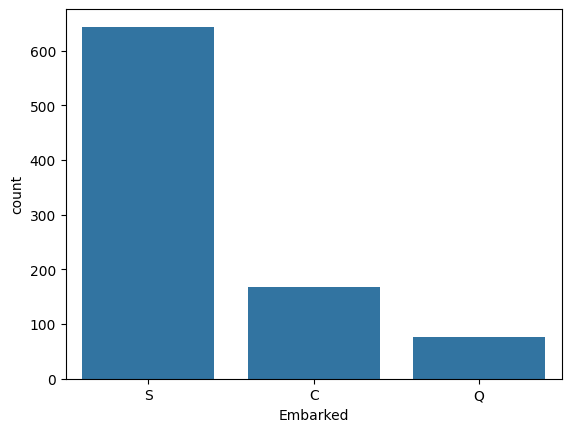

In [ ]:
sns.countplot(data=df, x=df['Embarked'])

In [ ]:
(df['Embarked'].value_counts() / len(df)) * 100

,count
Embarked,
S,72.278339
C,18.855219
Q,8.641975


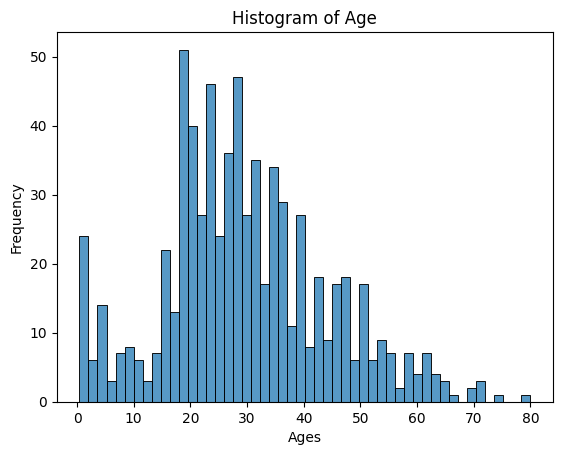

In [ ]:
sns.histplot(df['Age'],bins=50)

plt.title('Histogram of Age')
plt.xlabel('Ages')
plt.ylabel('Frequency')

plt.show()

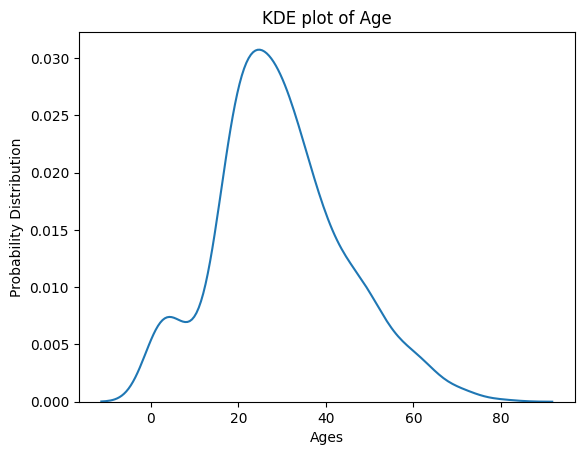

In [ ]:
sns.kdeplot(df['Age'])

plt.title('KDE plot of Age')
plt.xlabel('Ages')
plt.ylabel('Probability Distribution')

plt.show()

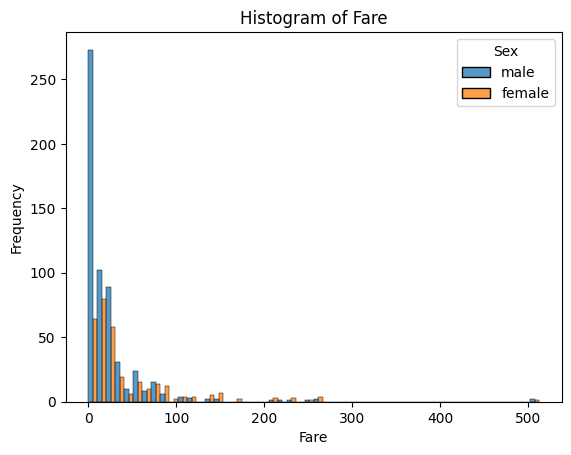

In [ ]:
sns.histplot(data=df, x='Fare', hue='Sex', bins=50, multiple='dodge')

plt.title('Histogram of Fare')
plt.xlabel('Fare')
plt.ylabel('Frequency')

plt.show()

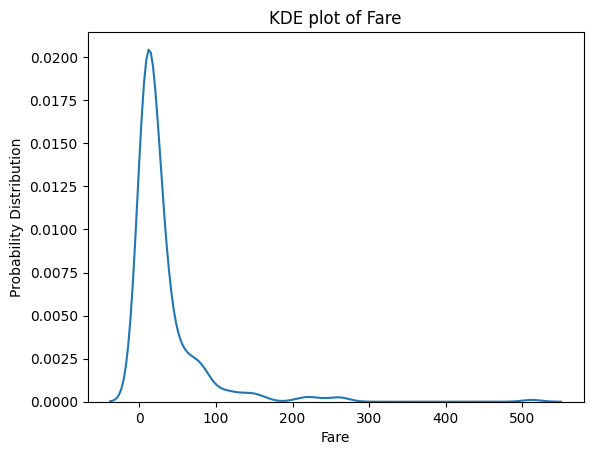

In [ ]:
sns.kdeplot(df['Fare'])

plt.title('KDE plot of Fare')
plt.xlabel('Fare')
plt.ylabel('Probability Distribution')

plt.show()

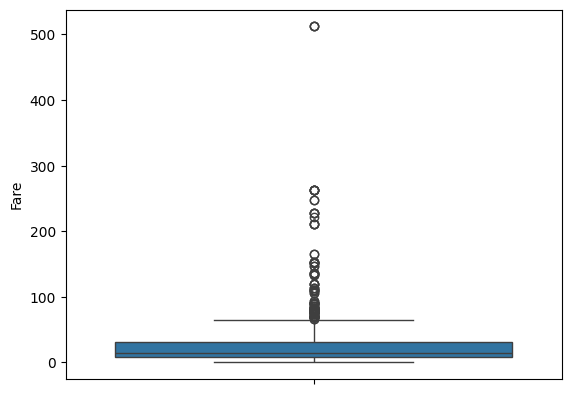

In [ ]:
sns.boxplot(df['Fare'])

plt.show()